In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
#Datos extraídos de Kaggle
df = pd.read_csv("application_train.csv.zip")

#Limpieza de Nan
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)

# Variables necesarias
df["RATIO_CREDITO_INGRESO"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
df["RATIO_ANUALIDAD_INGRESO"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
df["PROPORCION_VIDA_EMPLEADO"] = df["DAYS_EMPLOYED"] / df["DAYS_BIRTH"]

# Transformación de datos para uso del modelo
cat_cols = df.select_dtypes(include=["object"]).columns
for col in cat_cols:
    df[col] = df[col].astype("category")

# Separación de variables
X = df.drop(columns=["SK_ID_CURR", "TARGET","CODE_GENDER"])
y = df["TARGET"]

# Mantener el ~8% de impagos en ambos conjuntos
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Entrenamiento: {X_train.shape[0]} filas | Validación: {X_val.shape[0]} filas")

Entrenamiento: 246008 filas | Validación: 61503 filas


In [2]:
num_cols = X_train.select_dtypes(include=[np.number]).columns

baseline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=500, random_state=42)
)
baseline.fit(X_train[num_cols], y_train)
probs_base = baseline.predict_proba(X_val[num_cols])[:, 1]

print("--- COMPARATIVA DE MODELOS (VALIDACIÓN) ---")
print(f"Regresión Logística -> ROC-AUC: {roc_auc_score(y_val, probs_base):.4f} | PR-AUC: {average_precision_score(y_val, probs_base):.4f}")

--- COMPARATIVA DE MODELOS (VALIDACIÓN) ---
Regresión Logística -> ROC-AUC: 0.7385 | PR-AUC: 0.2209


In [3]:
modelo = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=1500,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=1.0,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1
)

modelo.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="auc",
    callbacks=[
        lgb.early_stopping(stopping_rounds=50, verbose=100),
        lgb.log_evaluation(period=100)
    ]
)

# Probabilidades predichas de caer en impago (clase 1)
probs_val = modelo.predict_proba(X_val)[:, 1]

print(f"LightGBM            -> ROC-AUC: {roc_auc_score(y_val, probs_val):.4f} | PR-AUC: {average_precision_score(y_val, probs_val):.4f}")

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.097116 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 12161
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 114
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
Training until validation scores don't improve for 50 rounds
[100]	valid_0's auc: 0.74978	valid_0's binary_logloss: 0.248993
[200]	valid_0's auc: 0.756725	valid_0's binary_logloss: 0.246362
[300]	valid_0's auc: 0.75879	valid_0's binary_logloss: 0.245657
[400]	valid_0's auc: 0.759218	valid_0's binary_logloss: 0.24549
Early stopping, best iteration is:
[382]	valid_0's auc: 0.75927	valid_0's binary_logloss: 0.245493
LightGBM            -

In [4]:
probs_val

array([0.05536184, 0.04268284, 0.1628141 , ..., 0.03711439, 0.11032567,
       0.17930292], shape=(61503,))

Umbral óptimo de rechazo (tau*): 0.173
Ganancia sin modelo:             $3,155,707,963.57
Ganancia con LightGBM (tau*):    $3,433,145,117.40
Valor agregado por el modelo:    $277,437,153.83


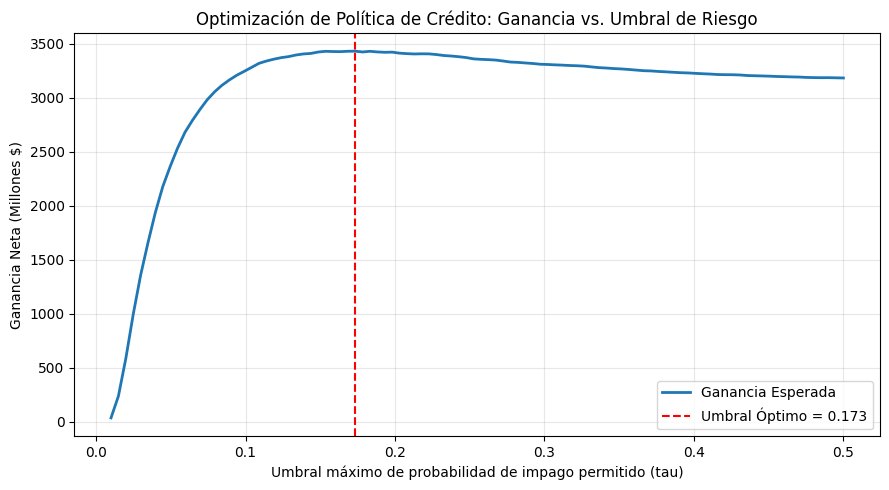

In [5]:
#Optimización de Umbral
y_val_arr = y_val.values
monto_val_arr = X_val["AMT_CREDIT"].values

umbrales = np.linspace(0.01, 0.50, 100)
ganancias = []

for tau in umbrales:
    # Aprobamos si la probabilidad de impago es menor al umbral tau
    aprobados = probs_val < tau

    # Si paga bien (y == 0), el banco gana 15% del préstamo en intereses
    ganancia_buenos = np.sum((1 - y_val_arr[aprobados]) * 0.15 * monto_val_arr[aprobados])

    # Si cae en impago (y == 1), el banco pierde 70% del capital prestado
    perdida_malos = np.sum(y_val_arr[aprobados] * 0.70 * monto_val_arr[aprobados])

    ganancias.append(ganancia_buenos - perdida_malos)

ganancias = np.array(ganancias)
idx_optimo = np.argmax(ganancias)
tau_optimo = umbrales[idx_optimo]
ganancia_maxima = ganancias[idx_optimo]

# Comparación contra aprobar a todos sin modelo (tau = 1.0)
ganancia_sin_modelo = np.sum((1 - y_val_arr) * 0.15 * monto_val_arr) - np.sum(y_val_arr * 0.70 * monto_val_arr)

print(f"Umbral óptimo de rechazo (tau*): {tau_optimo:.3f}")
print(f"Ganancia sin modelo:             ${ganancia_sin_modelo:,.2f}")
print(f"Ganancia con LightGBM (tau*):    ${ganancia_maxima:,.2f}")
print(f"Valor agregado por el modelo:    ${ganancia_maxima - ganancia_sin_modelo:,.2f}")

# Gráfica de la curva de beneficio esperado
plt.figure(figsize=(9, 5))
plt.plot(umbrales, ganancias / 1e6, label="Ganancia Esperada", color="#1f77b4", linewidth=2)
plt.axvline(tau_optimo, color="red", linestyle="--", label=f"Umbral Óptimo = {tau_optimo:.3f}")
plt.title("Optimización de Política de Crédito: Ganancia vs. Umbral de Riesgo")
plt.xlabel("Umbral máximo de probabilidad de impago permitido (tau)")
plt.ylabel("Ganancia Neta (Millones $)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("curva_ganancia.png", dpi=150)
plt.show()

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


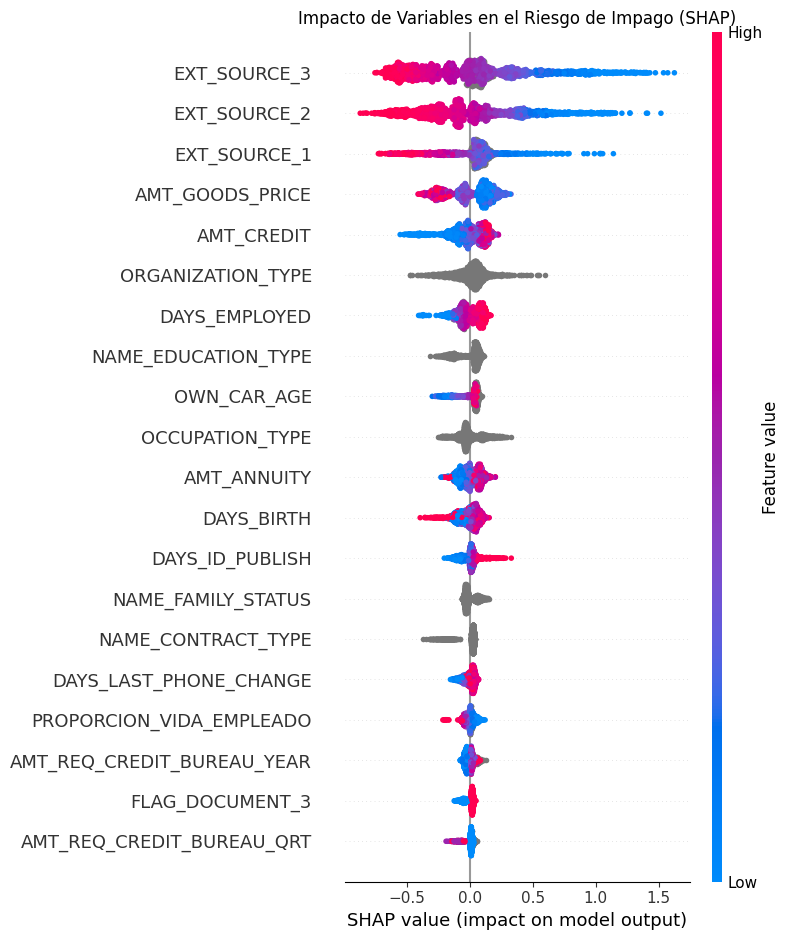

In [6]:
X_sample = X_val.sample(2000, random_state=42)

explainer = shap.TreeExplainer(modelo)
shap_values = explainer.shap_values(X_sample)


valores_clase_1 = shap_values[1] if isinstance(shap_values, list) else shap_values

plt.figure()
shap.summary_plot(valores_clase_1, X_sample, show=False)
plt.title("Impacto de Variables en el Riesgo de Impago (SHAP)")
plt.tight_layout()
plt.savefig("shap_importancia.png", dpi=150)
plt.show()